# 02 Choosing k for truncated SVD

Owner: Jeevan Mandala (ML Engineer)

We picked SVD as the main method before fitting anything. The matrix is sparse and has no negative values, SVD doesn't need centring, and it gives the customer and product factors the recommender uses. PCA comes later in notebook 04 with the same k.

k is picked from the error curve, the storage and fit time, and the hit rate on a validation period taken from the end of the training rows. The test purchases aren't touched in this notebook.

In [13]:
import sys
sys.path.insert(0, "../src")

import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from recommend import load_processed, fit_svd, relative_error, factor_size_mb

A, customer_index, product_index, eval_pairs = load_processed()
print("Matrix:", A.shape, "| non-zeros:", A.nnz)

Matrix: (5471, 3686) | non-zeros: 413691


## Fit for k = 10, 20, 50, 100, 200

In [14]:
KS = [10, 20, 50, 100, 200]
rows = []
for k in KS:
    start = time.perf_counter()
    svd = fit_svd(A, k)  # random_state is fixed inside fit_svd
    fit_seconds = time.perf_counter() - start
    error = relative_error(A, svd)
    rows.append({
        "k": k,
        "fit_seconds": round(fit_seconds, 2),
        "relative_error": round(error, 4),
        "matrix_energy_kept_%": round((1 - error**2) * 100, 1),
        "factors_MB": round(factor_size_mb(A, k), 2),
    })
    print("done k =", k)

results = pd.DataFrame(rows)
# how much the error drops per extra component compared with the previous k
results["error_drop_per_component"] = (
    -results["relative_error"].diff() / results["k"].diff()
).round(5)
results

done k = 10
done k = 20
done k = 50
done k = 100
done k = 200


,k,fit_seconds,relative_error,matrix_energy_kept_%,factors_MB,error_drop_per_component
0,10,0.06,0.8759,23.3,0.70,NaN
1,20,0.09,0.8457,28.5,1.40,0.00302
2,50,0.15,0.7895,37.7,3.49,0.00187
3,100,0.28,0.7275,47.1,6.99,0.00124
4,200,0.55,0.6390,59.2,13.97,0.00089


## Curves

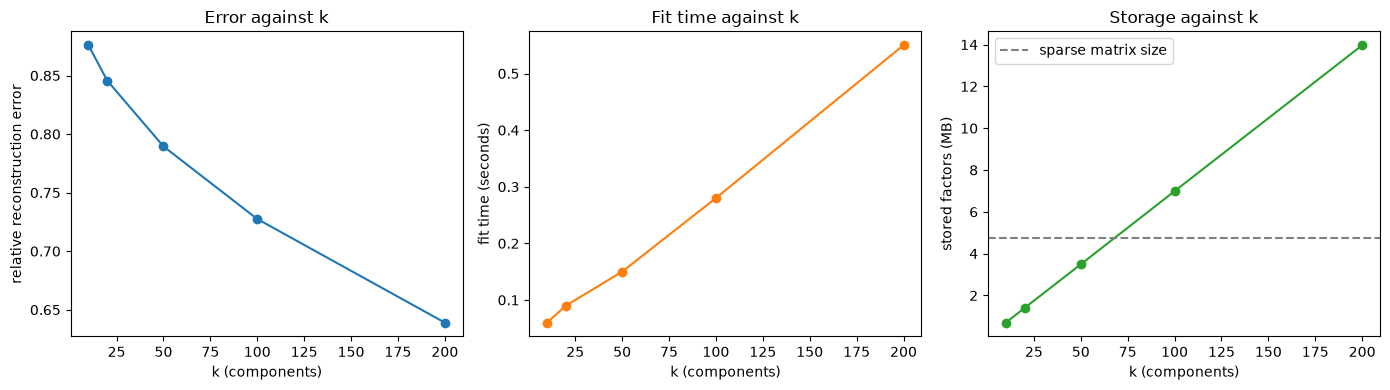

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(results["k"], results["relative_error"], marker="o")
axes[0].set_xlabel("k (components)")
axes[0].set_ylabel("relative reconstruction error")
axes[0].set_title("Error against k")

axes[1].plot(results["k"], results["fit_seconds"], marker="o", color="tab:orange")
axes[1].set_xlabel("k (components)")
axes[1].set_ylabel("fit time (seconds)")
axes[1].set_title("Fit time against k")

axes[2].plot(results["k"], results["factors_MB"], marker="o", color="tab:green")
axes[2].axhline(A.data.nbytes / 1024**2 + A.indices.nbytes / 1024**2,
                linestyle="--", color="gray", label="sparse matrix size")
axes[2].set_xlabel("k (components)")
axes[2].set_ylabel("stored factors (MB)")
axes[2].set_title("Storage against k")
axes[2].legend()

plt.tight_layout()
plt.savefig("../outputs/figures/svd_k_selection.png", dpi=150)
plt.show()

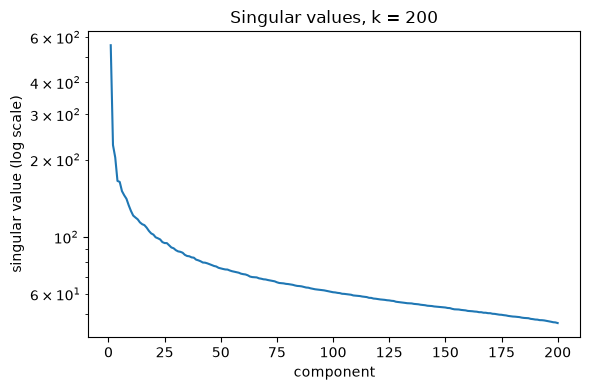

In [16]:
# singular values from the biggest fit; a big first value means one dominant direction
svd_200 = fit_svd(A, 200)
plt.figure(figsize=(6, 4))
plt.semilogy(range(1, 201), svd_200.singular_values_)
plt.xlabel("component")
plt.ylabel("singular value (log scale)")
plt.title("Singular values, k = 200")
plt.tight_layout()
plt.savefig("../outputs/figures/svd_singular_values.png", dpi=150)
plt.show()

In [17]:
import numpy as np
from split import time_split
from matrix import build_matrix, restrict_eval_pairs
from recommend import (PROCESSED, product_vectors, recommend_for_customers, recommend_blend,
                       best_seller_baseline, hits_at_n, bootstrap_ci)

# split the training rows again, their last 2 months become a validation period
train = pd.read_pickle(PROCESSED / "train_transactions.pkl")
inner_train, validation, val_held_out, val_info = time_split(train, months=2)
A_val, val_customers, val_products, _ = build_matrix(inner_train, 10)
val_pairs, _ = restrict_eval_pairs(val_held_out, val_customers, val_products)
val_rows = np.sort(val_pairs["customer_idx"].unique())

baseline = hits_at_n(best_seller_baseline(A_val, val_rows), val_rows,
                     val_pairs, A_val.shape).mean()

# cosine is the ML3 scoring, reconstruct is the row of the rank-k matrix (see notebook 03)
VAL_KS = [10, 20, 50, 100, 150, 200]
rows = []
for k in VAL_KS:
    svd_k = fit_svd(A_val, k)
    cosine_hits = hits_at_n(recommend_for_customers(A_val, product_vectors(svd_k), val_rows),
                            val_rows, val_pairs, A_val.shape)
    recon_hits = hits_at_n(recommend_blend(A_val, svd_k, val_rows, mode="reconstruct", alpha=1.0),
                           val_rows, val_pairs, A_val.shape)
    low, high = bootstrap_ci(recon_hits)
    rows.append({"k": k,
                 "cosine_hit_rate": round(cosine_hits.mean(), 4),
                 "reconstruct_hit_rate": round(recon_hits.mean(), 4),
                 "reconstruct_ci_low": round(low, 4),
                 "reconstruct_ci_high": round(high, 4)})

validation_results = pd.DataFrame(rows)
validation_results["baseline"] = round(baseline, 4)
validation_results.to_csv("../outputs/results/svd_k_validation.csv", index=False)
print("Validation customers:", len(val_rows))
validation_results

Validation customers: 1415


,k,cosine_hit_rate,reconstruct_hit_rate,reconstruct_ci_low,reconstruct_ci_high,baseline
0,10,0.1527,0.3208,0.2982,0.3449,0.2643
1,20,0.1781,0.3470,0.3237,0.3710,0.2643
2,50,0.2325,0.3746,0.3491,0.4007,0.2643
3,100,0.2269,0.3901,0.3654,0.4148,0.2643
4,150,0.2177,0.3767,0.3512,0.4021,0.2643
5,200,0.2120,0.3774,0.3534,0.4028,0.2643


## Decision

There's no clear elbow in the error curve. The relative error goes from 0.876 at k = 10 down to 0.639 at k = 200, and each extra component helps a bit less than the last, so the curve alone can't tell us k. At k = 50 the model keeps about 38% of the matrix energy.

On the validation period the reconstruct scoring gets hit rates of 0.321, 0.347, 0.375, 0.390, 0.377 and 0.377 for k = 10, 20, 50, 100, 150 and 200, against 0.264 for the best sellers. It stops improving after k = 100. The cosine scoring from the brief stays under the baseline at every k (0.153 to 0.233).

Our rule was to take the smallest k that's within one percentage point of the best hit rate. The best is 0.3901 at k = 100, and k = 50 is 1.6 points lower, so we went with k = 100.

At k = 100 the fit takes about 0.3 s and the factors are 6.99 MB. That's 22 times smaller than the dense matrix (153.9 MB) but bigger than the sparse one (4.8 MB). The factors only get below the sparse size for k under about 68.

In [18]:
best = validation_results["reconstruct_hit_rate"].max()
close_enough = validation_results["reconstruct_hit_rate"] >= best - 0.01
CHOSEN_K = int(validation_results.loc[close_enough, "k"].min())

results.to_csv("../outputs/results/svd_k_selection.csv", index=False)
Path("../outputs/results/chosen_k.txt").write_text(str(CHOSEN_K))
print("Best validation hit rate:", best, "| chosen k:", CHOSEN_K)

Best validation hit rate: 0.3901 | chosen k: 100
